In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata
import scanpy as sc
import scvelo as scv
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


In [3]:
adata = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_full.h5ad')
adata.obs.set_index('CellID', inplace=True)
annotation = pd.read_csv('INPUT/scRNAseq/theta_Zspace_annotation.csv').set_index('CellID')
new_obs = adata.obs.merge(annotation,left_index= True, right_index=True, how = 'inner')
adata = adata[new_obs.index]
adata.obs = new_obs


## Theta space densities

In [4]:
# Filtering
adata.var_names_make_unique()
sc.pp.filter_cells(adata, min_counts=1000)
adata.obs['UMI_SUM'] = adata.X.sum(axis = 1)
scv.pp.normalize_per_cell(adata, layers = [ 'spliced', 'unspliced'] )  

# Log all layers log(1+x)
sc.pp.log1p(adata)  
sc.pp.log1p(adata, layer='spliced')
sc.pp.log1p(adata, layer='unspliced')


Normalized count data: X, spliced, unspliced.


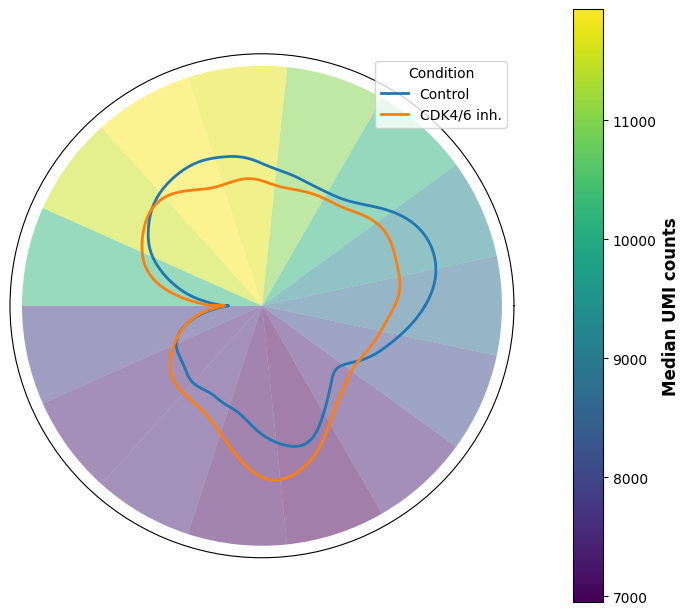

In [5]:


adata_plot = adata[
    (adata.obs['Time_int'] > 65) &
    (adata.obs['Condition'] != 'porcn')
].copy()

# Convert to DataFrame from the filtered AnnData
df = adata_plot.obs[['inferred_theta', 'Condition', 's_counts']].copy()

# Conditions and palette
conditions = ['ctrl', 'cdk']
palette = {'ctrl': 'tab:blue', 'cdk': 'tab:orange'}

# Display labels for legend
label_map = {
    'ctrl': 'Control',
    'cdk': 'CDK4/6 inh.'
}

# ----------------------------
# Settings
# ----------------------------
bw_adjust = 0.5
n_bins = 15
theta_grid = np.linspace(-np.pi, np.pi, 512, endpoint=False)

# ----------------------------
# Background: median UMI counts vs angle
# ----------------------------
theta_bins = np.linspace(-np.pi, np.pi, n_bins + 1)
theta_centers = 0.5 * (theta_bins[:-1] + theta_bins[1:])
theta_centers_plot = (theta_centers + 2*np.pi) % (2*np.pi)

bg = np.zeros(n_bins, dtype=float)
theta_vals = df['inferred_theta'].astype(float).values
ncounts_vals = df['s_counts'].astype(float).values

for i in range(n_bins):
    m = (theta_vals >= theta_bins[i]) & (theta_vals < theta_bins[i+1])
    bg[i] = np.median(ncounts_vals[m])

# Normalisation for colormap
bg_min = np.nanmin(bg)
bg_max = np.nanmax(bg)
bg_norm = (bg - bg_min) / (bg_max - bg_min) if bg_max > bg_min else bg

# ----------------------------
# Polar plot
# ----------------------------
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

# Background ring
ax.bar(
    theta_centers_plot,
    height=0.3,
    width=(2*np.pi / n_bins),
    bottom=0.0,
    color=plt.cm.viridis(bg_norm),
    alpha=0.50,
    edgecolor='none',
    zorder=0
)

# ----------------------------
# KDE curves (per condition)
# ----------------------------
theta_plot = (theta_grid + 2*np.pi) % (2*np.pi)
order = np.argsort(theta_plot)
theta_plot_sorted = theta_plot[order]
theta_grid_sorted = theta_grid[order]

for cond in conditions:
    m = df['Condition'].str.lower() == cond
    x = df.loc[m, 'inferred_theta'].astype(float).dropna().values
    if x.size == 0:
        continue

    kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
    density = kde(theta_grid_sorted)

    th = np.r_[theta_plot_sorted, theta_plot_sorted[0] + 2*np.pi]
    rr = np.r_[density, density[0]]

    ax.plot(
        th, rr,
        color=palette[cond],
        lw=2,
        label=label_map.get(cond, cond),
        zorder=2
    )

# ----------------------------
# Formatting
# ----------------------------
ax.set_thetalim(0, 2*np.pi)
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)

ax.set_xticks([])
ax.set_yticks([])
ax.set_ylabel(None)

ax.legend(title='Condition', loc='upper right')

# ----------------------------
# Colorbar for UMI counts
# ----------------------------
norm = Normalize(vmin=bg_min, vmax=bg_max)
sm = ScalarMappable(norm=norm, cmap='viridis')
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    pad=0.10,
    fraction=0.05
)
cbar.set_label(
    "Median UMI counts",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


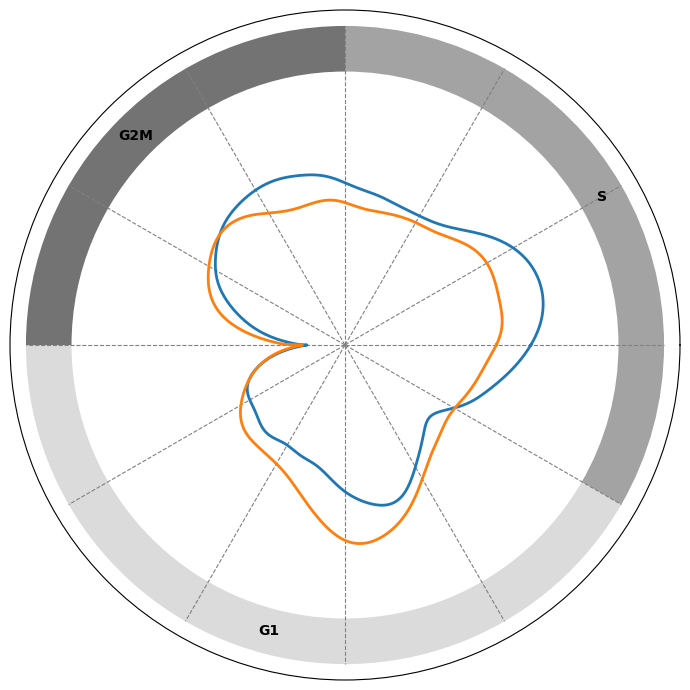

In [ ]:
# ---- Phase annotation ring 
def add_phase_band(ax, segments, r0=0.3, band_height=0.05, alpha=0.95, edgecolor="none"):
    def wrap(a):
        return (a + 2 * np.pi) % (2 * np.pi)

    for seg in segments:
        start = wrap(seg["start"])
        end = wrap(seg["end"])
        direction = seg.get("direction", "ccw").lower()
        col = seg.get("color", "lightgrey")

        if direction == "ccw":
            width = (end - start) % (2 * np.pi)
            start_draw = start
        elif direction == "cw":
            width = (start - end) % (2 * np.pi)
            start_draw = end
        else:
            raise ValueError("direction must be 'ccw' or 'cw'")

        center = start_draw + width / 2

        ax.bar(
            x=center, height=band_height, width=width, bottom=r0,
            color=col, alpha=alpha, edgecolor=edgecolor, align="center", zorder=0
        )
        ax.text(
            center, r0 + band_height / 2, seg["label"],
            fontsize=10, fontweight="bold", ha="center", va="center", zorder=1
        )

# ---- Phase segments
phase_segments = [
    {"label": "G1",  "start": np.pi,     "end": -np.pi/6, "direction": "ccw", "color": "#d9d9d9"},
    {"label": "S",   "start": -np.pi/6,  "end":  np.pi/2, "direction": "ccw", "color": "#9e9e9e"},
    {"label": "G2M", "start": np.pi/2,   "end":  np.pi,   "direction": "ccw", "color": "#6b6b6b"},
]

adata_plot = adata[
    (adata.obs["Time_int"] > 65) &
    (adata.obs["Condition"] != "porcn")
].copy()
df = adata_plot.obs[["inferred_theta", "Condition", "s_counts"]].copy()

conditions = ["ctrl", "cdk"]
palette = {"ctrl": "tab:blue", "cdk": "tab:orange"}
label_map = {"ctrl": "Control", "cdk": "CDK4/6 inh."}
bw_adjust = 0.5
theta_grid = np.linspace(-np.pi, np.pi, 512, endpoint=False)

# ---- Plot setup
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
ax.set_thetalim(0, 2 * np.pi)
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

# Remove all default ticks and labels
ax.set_xticks([])
ax.set_yticks([])
ax.set_ylabel(None)

# ---- Outer phase ring
r0 = 0.3
band_height = 0.05
add_phase_band(ax, phase_segments, r0=r0, band_height=band_height)

#
slice_angles = np.linspace(-np.pi, np.pi, 12, endpoint=False)  # 12 slices
r_max = r0 + band_height
for angle in slice_angles:
    ax.plot([angle, angle], [0, r_max], color="grey", lw=0.8, linestyle="--", zorder=0)

# ---- KDE curves per condition
theta_plot = (theta_grid + 2 * np.pi) % (2 * np.pi)
order = np.argsort(theta_plot)
theta_plot_sorted = theta_plot[order]
theta_grid_sorted = theta_grid[order]

for cond in conditions:
    m = df["Condition"].str.lower() == cond
    x = df.loc[m, "inferred_theta"].astype(float).dropna().values
    if x.size == 0:
        continue

    kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
    density = kde(theta_grid_sorted)

    th = np.r_[theta_plot_sorted, theta_plot_sorted[0] + 2 * np.pi]
    rr = np.r_[density, density[0]]

    ax.plot(th, rr, color=palette[cond], lw=2, label=label_map.get(cond, cond), zorder=2)

plt.tight_layout()
fig.savefig(
    "FIGURES/Cellcycle_phase_conditions.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)
plt.show()


## Cell cycle RNA velocity

In [9]:
adata=adata[adata.obs['Condition'] =='ctrl']

In [10]:
list_all_genes = adata.var.reset_index().Gene.unique()


cell_cycle_genes = np.array(['KIF2C', 'BRIP1', 'MYBL2', 'FBXO5', 'RRM1', 'JPT1', 'KIFC1',
       'CKAP5', 'MKI67', 'DTL', 'TMPO', 'PARP2', 'CENPF', 'NEK2',
       'GAS2L3', 'ANP32E', 'CDKN1A', 'HIST1H1E', 'SPC25', 'PIMREG',
       'CEP128', 'KIF18A', 'PBK', 'CDCA3', 'RFC3', 'MCM4', 'MSH2',
       'CDC20', 'HIST1H2BJ', 'UBE2C', 'CIT', 'TRIM59', 'FAM111A', 'SLBP',
       'MCM6', 'SMC4', 'BORA', 'CDCA2', 'NASP', 'HIST1H2AM', 'EFNB2',
       'CENPE', 'KIF23', 'ARL6IP1', 'KNSTRN', 'CDCA4', 'MCM5', 'KIF4A',
       'AURKB', 'MCM2', 'USP1', 'ASPM', 'HMGB2', 'SNHG30', 'TIPIN',
       'NAV2', 'CDKN3', 'CCP110', 'KIF11', 'BIRC5', 'TPX2', 'E2F1',
       'CCNF', 'KIF20B', 'RAD54L', 'MND1', 'HIST1H2AB', 'CCNA2',
       'RAD51AP1', 'MSH6', 'GTSE1', 'WDR76', 'PUS7', 'PSRC1', 'EXO1',
       'CDCA8', 'CDKN2D', 'HIST1H1C', 'HJURP', 'CKS2', 'OIP5', 'KIF20A',
       'CCNE2', 'FAM83D', 'CCNB1', 'PLK1', 'HIST1H4D', 'CKS1B', 'CTCF',
       'TOP2A', 'NDE1', 'ZNF367', 'RANGAP1', 'AURKA', 'HIST1H2AH',
       'TUBB4B', 'CASP8AP2', 'CDK1', 'CHAF1B', 'DUSP5', 'NCAPD2',
       'HIST1H2BD', 'CDC6', 'HIST1H1B', 'DNA2', 'KLHL23', 'SGO1', 'BCL2',
       'ORC1', 'MZT1', 'DLGAP5', 'MNS1', 'CKAP2L', 'NCAPH', 'G0S2',
       'GINS2', 'DSCC1', 'LBR', 'CBX5', 'SAPCD2', 'SGO2', 'CLSPN',
       'NUSAP1', 'HIST1H2AC', 'ECT2', 'ANLN', 'CENPQ', 'TEX30',
       'HIST1H2BN', 'CDC25C', 'CENPA', 'POLD3', 'UHRF1', 'FAM111B',
       'PIF1', 'RFC2', 'E2F8', 'POLA1', 'BLM', 'CDCA7', 'HIST1H4C',
       'HIST2H2AC', 'NDC80', 'NEIL3', 'HIST2H2BE', 'BUB1', 'TTK', 'BRD8',
       'CDC45', 'CENPL', 'RRM2', 'PAQR4', 'BATF3', 'KITLG', 'HIST1H2BC',
       'ASF1B', 'HIST1H4H', 'HMMR', 'DEPDC1', 'NUF2', 'BUB1B', 'HELLS',
       'PRIM1', 'TNFAIP8L1', 'KNL1', 'DBF4', 'ATAD2', 'POLE2', 'CEP55',
       'ORC6', 'STIL', 'PCNA', 'MCM3', 'GMNN', 'UBE2S', 'CENPU', 'G2E3',
       'KPNA2', 'TYMS', 'CKAP2', 'CENPI', 'HIST1H3B', 'KIF14', 'KIF15',
       'ESCO2', 'UBR7', 'UNG', 'HIST1H3C', 'CCNB2', 'PRC1', 'RPA2'
       'CDC25B', 'RAD51', 'TACC3', 'hp', 'hist2h3c2-ps', 'cyp2f2', 'ghr', 'lcn2', 'tcp11l2', 'hist1h2bc', 'ogn', 'gbp2', 'vnn1', 'rab27b', 'saa3', 'hist2h2be', 'ptgfr', 'ddx58', 
       'mcm6', 'ccne2','esco2', 'hist1h1b','top2a', 'cdk1','aurka', 'tuba1c','cenpa', 'cdkn3'])




cell_cycle_genes  = [a.lower() for a in cell_cycle_genes ]
adata_cc = adata[:,np.intersect1d(cell_cycle_genes,list_all_genes)]
X_umap = np.array([adata_cc.obs['theta_1'].values, adata_cc.obs['theta_2'].values]).T


In [11]:
def processing(adata_, phase,  velo):
    
    adata_ = adata_[~adata_.to_df().duplicated(),:]
    if phase:
        scv.tl.score_genes_cell_cycle(adata_)

    if (velo ==True):
        scv.pp.moments(adata_)
        scv.tl.recover_dynamics(adata_, n_jobs=5)
        adata_ = adata_[~adata_.to_df().duplicated(),:]
        scv.tl.velocity(adata_, mode='deterministic')
        scv.tl.velocity_graph(adata_)

    return adata_

sc.pp.pca(adata_cc)
sc.pp.neighbors(adata_cc)
adata_cc.obsm['X_umap'] = X_umap

# Compute velocity fields
adata_cc = processing(adata_cc, phase = False, velo =True)

computing neighbors
    finished (0:00:05) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 5/96 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:00:49) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/96 cores)
    finished (0:00:11) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:03) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


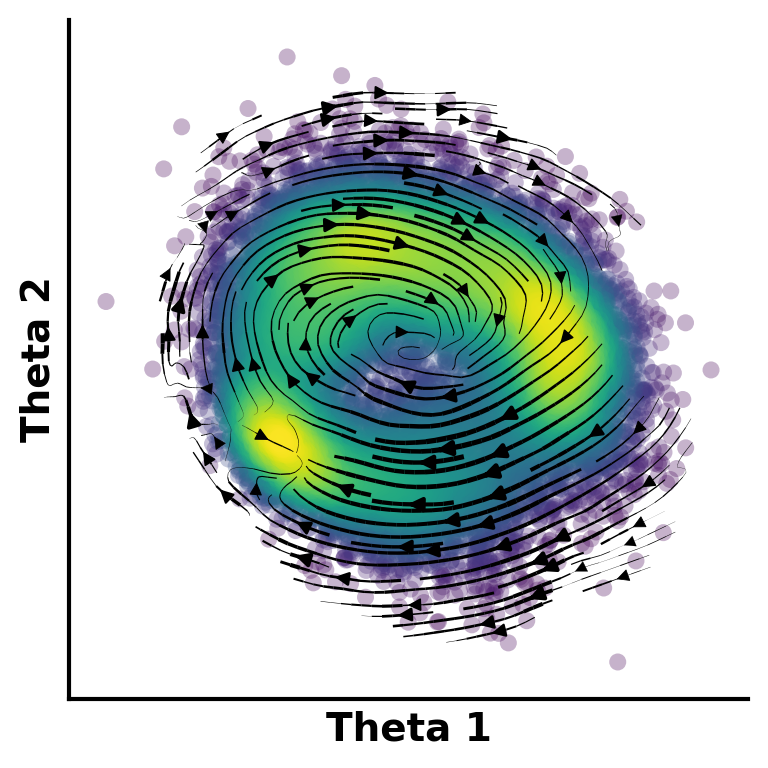

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc
import scvelo as scv
import cmcrameri.cm as cmc
from matplotlib import rcParams
from matplotlib.colors import ListedColormap
color = "umap_density"
# Define colormaps
colormaps = {
    "umap_density": "viridis"
    
}

# Configure figure parameters in scvelo
scv.set_figure_params(
    style="scvelo",
    dpi=100,
    dpi_save=150,
    frameon=True, 
    transparent=True,
    fontsize=12,
    figsize=(4, 5),
    color_map=None, 
    facecolor="white",
    format="pdf",
)


rcParams["axes.spines.top"] = False
rcParams["axes.spines.right"] = False
rcParams["axes.spines.bottom"] = True
rcParams["axes.spines.left"] = True
rcParams["axes.linewidth"] = 1.5  

# Compute embedding density
sc.tl.embedding_density(adata_cc, basis="umap")

# Create figure and axes
fig, ax = plt.subplots(1, 1, figsize=(4, 4))

# Generate plots
scv.pl.velocity_embedding_stream(
    adata_cc,
    basis="umap",
    color=color,
    size=150,
  
    legend_fontsize=12,  
    cmap=colormaps[color],  
    ax=ax,  
    show=False,  
    colorbar = False
)

# Adjust legend position manually
leg = ax.get_legend()
if leg:
    leg.set_bbox_to_anchor((1.05, 1.05)) 
    leg.get_frame().set_linewidth(0.8) 

# Remove title
ax.set_title("")

# Set axis labels
ax.set_xlabel("Theta 1", fontsize=14, fontweight = 'bold')
ax.set_ylabel("Theta 2", fontsize=14, fontweight = 'bold')

# Adjust axis limits to give more space around the points
xlim, ylim = ax.get_xlim(), ax.get_ylim()
ax.set_xlim(xlim[0] - 0.05 * (xlim[1] - xlim[0]), xlim[1] + 0.05 * (xlim[1] - xlim[0]))
ax.set_ylim(ylim[0] - 0.05 * (ylim[1] - ylim[0]), ylim[1] + 0.05 * (ylim[1] - ylim[0]))

plt.tight_layout()

fig.savefig(
    "FIGURES/theta_space_velocity.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


In [13]:

ectoderm = ['Neuroectoderm/NMPs', 'Early neuroectoderm/NMPs' ]
endoderm = ['Endoderm', 'Early endoderm' ]
mesoderm = [ 'Cardiac mesoderm', 'Early cardiac mesoderm',  'Early somitic mesoderm','Somitic mesoderm' ]
primitive_tissues = ['Epiblast','Ectopic pluripotency'
                     'Primitive streak' , 'Naive pluripotency']
porcn_cluster = ['Wnt. inh. state']

# Create an empty dictionary to store the mappings
germ_layers = {}

# Populate the dictionary with the mappings
for item in ectoderm:
    germ_layers[item] = 'Neuroectoderm/NMPs'

for item in endoderm:
    germ_layers[item] = 'Endoderm'

for item in mesoderm:
    germ_layers[item] = 'Mesoderm'

for item in primitive_tissues:
    germ_layers[item] = 'Early tissues'

for item in porcn_cluster:
    germ_layers[item] = 'Wnt. inhibitor'

adata.obs['BIG_celltype'] = adata.obs['Cell type'].map(germ_layers)

## Cell cycle characteristics

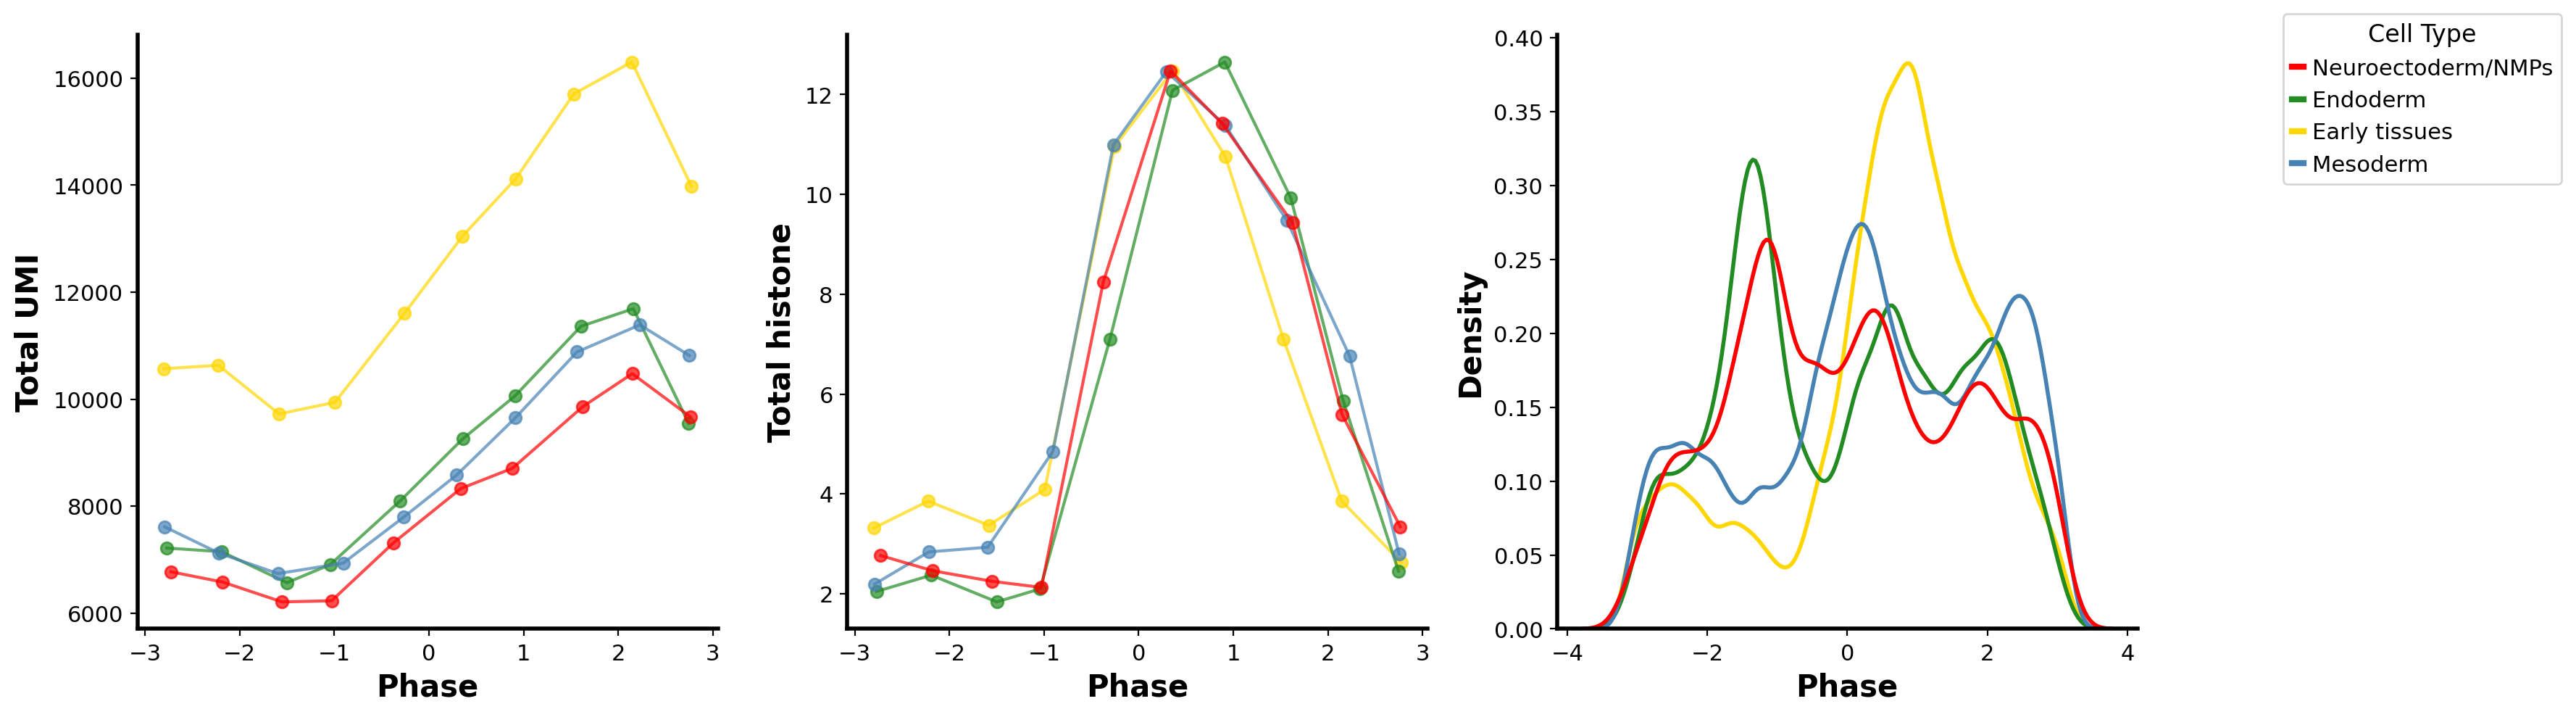

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

# Fixed colormap
color_map = {
    'Neuroectoderm/NMPs': 'red',
    'Endoderm': 'forestgreen',
    'Early tissues': 'gold',
    'Mesoderm': 'steelblue',
}

# Select genes starting with 'hist'
histone_genes = [gene for gene in adata.var_names if gene.startswith('hist')]

# Compute sums per cell
adata.obs['histone_sum'] = adata[:, histone_genes].X.sum(axis=1).A1
adata.obs['umi_sum'] = adata.X.sum(axis=1).A1

# Convert to DataFrame
df = adata.obs[['inferred_theta', 'histone_sum', 'umi_sum', 'UMI_SUM', 'BIG_celltype']].copy()


df = df[df['BIG_celltype'].isin(color_map.keys())].copy()

# Define bins
num_bins = 10
df['bin'] = pd.cut(df['inferred_theta'], bins=num_bins, labels=False)

# Compute per-bin summaries
binned_df = df.groupby(['BIG_celltype', 'bin']).agg({
    'inferred_theta': 'median',
    'histone_sum': 'median',
    'UMI_SUM': 'median',
}).reset_index()

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

# --- Plot total UMI ---
for cell_type, group in binned_df.groupby('BIG_celltype'):
    axes[0].plot(
        group['inferred_theta'], group['UMI_SUM'],
        color=color_map[cell_type], alpha=0.7, marker='o'
    )
axes[0].set_xlabel('Phase', fontsize=15, fontweight='bold')
axes[0].set_ylabel('Total UMI', fontsize=15, fontweight='bold')

# --- Plot total histone ---
for cell_type, group in binned_df.groupby('BIG_celltype'):
    axes[1].plot(
        group['inferred_theta'], group['histone_sum'],
        color=color_map[cell_type], alpha=0.7, marker='o'
    )
axes[1].set_xlabel('Phase', fontsize=15, fontweight='bold')
axes[1].set_ylabel('Total histone', fontsize=15, fontweight='bold')

# --- Plot phase density ---
for cell_type, group in df.groupby('BIG_celltype'):
    sns.kdeplot(
        group['inferred_theta'],
        ax=axes[2],
        color=color_map[cell_type],
        fill=False,      
        alpha=1.0,
        bw_adjust=0.5,
        linewidth=2,
        legend=False
    )
axes[2].set_xlabel('Phase', fontsize=15, fontweight='bold')
axes[2].set_ylabel('Density', fontsize=15, fontweight='bold')

for ax in axes:
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)

present_types = [ct for ct in color_map if ct in df['BIG_celltype'].unique()]
handles = [Line2D([0], [0], lw=3, color=color_map[ct]) for ct in present_types]
fig.legend(handles, present_types, title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
fig.savefig(
    "FIGURES/Cellcycle_phase_char_linear.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


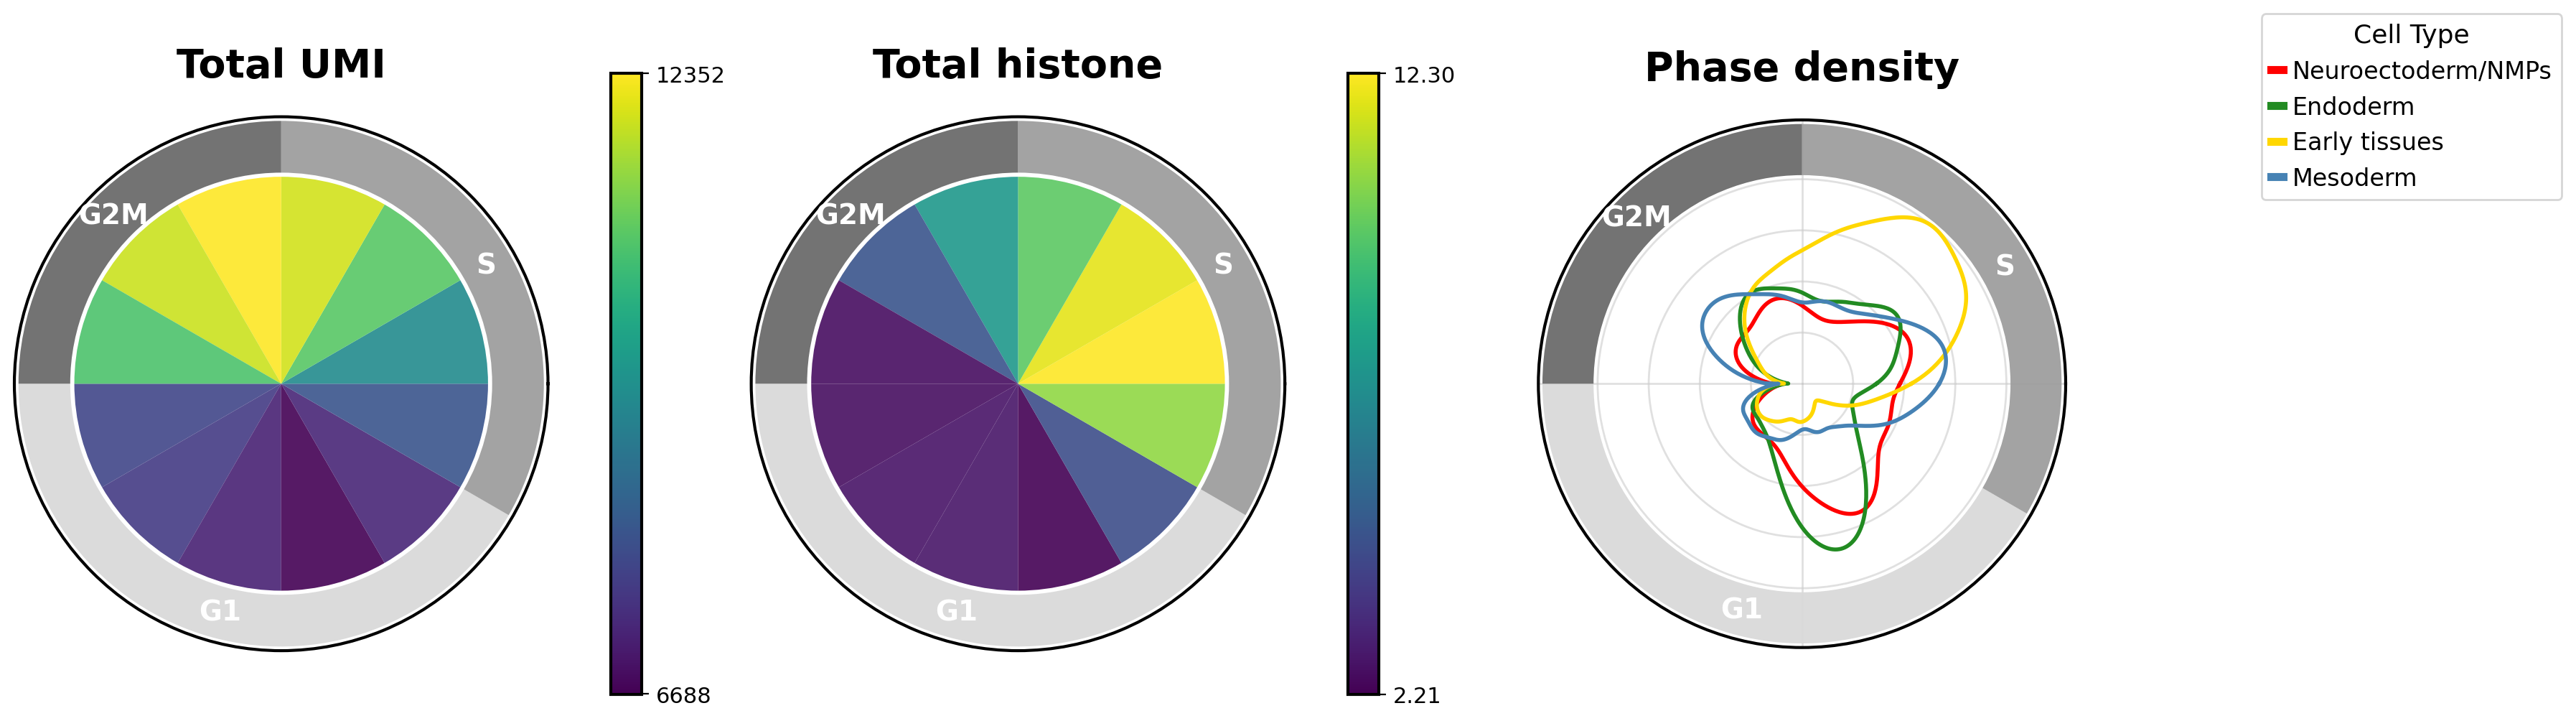

In [ ]:
def add_phase_band(ax, segments, r0=1.02, band_height=0.13, alpha=0.95, edgecolor="none"):
    def wrap(a):
        return (a + 2 * np.pi) % (2 * np.pi)

    for seg in segments:
        start = wrap(seg["start"])
        end = wrap(seg["end"])
        direction = seg.get("direction", "ccw").lower()
        col = seg.get("color", "lightgrey")

        if direction == "ccw":
            width = (end - start) % (2 * np.pi)
            start_draw = start
        elif direction == "cw":
            width = (start - end) % (2 * np.pi)
            start_draw = end
        else:
            raise ValueError("direction must be 'ccw' or 'cw'")

        center = start_draw + width / 2

        ax.bar(
            x=center,
            height=band_height,
            width=width,
            bottom=r0,
            color=col,
            alpha=alpha,
            edgecolor=edgecolor,
            align="center",
            zorder=5
        )
        ax.text(
            center,
            r0 + band_height / 2,
            seg["label"],
            fontsize=14,
            fontweight="bold",
            color="white",
            ha="center",
            va="center",
            zorder=6
        )

    ax.set_rlim(0, r0 + band_height + 0.02)


# Cell-type colours (panel c)
color_map = {
    "Neuroectoderm/NMPs": "red",
    "Endoderm": "forestgreen",
    "Early tissues": "gold",
    "Mesoderm": "steelblue",
}

# Phase annotation (angles in [-pi, pi])
phase_segments = [
    {"label": "G1",  "start": np.pi,     "end": -np.pi/6, "direction": "ccw", "color": "#d9d9d9"},
    {"label": "S",   "start": -np.pi/6,  "end":  np.pi/2, "direction": "ccw", "color": "#9e9e9e"},
    {"label": "G2M", "start": np.pi/2,   "end":  np.pi,   "direction": "ccw", "color": "#6b6b6b"},
]

# Histone sums
histone_genes = [g for g in adata.var_names if g.startswith("hist")]
adata.obs["histone_sum"] = adata[:, histone_genes].X.sum(axis=1).A1

df = adata.obs[["inferred_theta", "histone_sum", "UMI_SUM", "BIG_celltype"]].copy()
df = df[df["BIG_celltype"].isin(color_map.keys())].copy()

# Binning in [-pi, pi]
num_bins = 12
theta_bins = np.linspace(-np.pi, np.pi, num_bins + 1)
theta_centers = 0.5 * (theta_bins[:-1] + theta_bins[1:])
theta_centers_plot = (theta_centers + 2 * np.pi) % (2 * np.pi)

df["bin"] = pd.cut(
    df["inferred_theta"],
    bins=theta_bins,
    labels=False,
    include_lowest=True
)

bg = (
    df.groupby("bin")
      .agg(umi=("UMI_SUM", "median"), histone=("histone_sum", "median"))
      .reindex(range(num_bins))
)

umi_norm = Normalize(bg["umi"].min(), bg["umi"].max())
hist_norm = Normalize(bg["histone"].min(), bg["histone"].max())

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    subplot_kw={"projection": "polar"}
)

for ax in axes:
    ax.set_thetalim(0, 2 * np.pi)
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)
    ax.set_xticks([])
    ax.set_yticks([])

TITLE_FONTSIZE = 20

# (a) UMI ring
axes[0].bar(
    theta_centers_plot,
    height=1.0,
    width=2 * np.pi / num_bins,
    bottom=0.0,
    color=plt.cm.viridis(umi_norm(bg["umi"].values)),
    edgecolor="none",
    alpha=0.9,
    zorder=1
)
axes[0].set_rlim(0, 1.06)
axes[0].set_title("Total UMI", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)

# (b) Histone ring
axes[1].bar(
    theta_centers_plot,
    height=1.0,
    width=2 * np.pi / num_bins,
    bottom=0.0,
    color=plt.cm.viridis(hist_norm(bg["histone"].values)),
    edgecolor="none",
    alpha=0.9,
    zorder=1
)
axes[1].set_title("Total histone", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)

# (c) Phase density (polar KDE)
bw_adjust = 0.5
theta_grid = np.linspace(-np.pi, np.pi, 512, endpoint=False)
theta_plot = (theta_grid + 2 * np.pi) % (2 * np.pi)
order = np.argsort(theta_plot)

densities = {}
global_max = 0.0

for ct in color_map:
    x = df.loc[df["BIG_celltype"] == ct, "inferred_theta"].dropna().values
    if x.size == 0:
        continue
    kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
    dens = kde(theta_grid[order])
    densities[ct] = dens
    global_max = max(global_max, float(np.nanmax(dens)))

for ct, dens in densities.items():
    dens_scaled = dens / global_max if global_max > 0 else dens
    th = np.r_[theta_plot[order], theta_plot[order][0] + 2 * np.pi]
    rr = np.r_[dens_scaled, dens_scaled[0]]
    axes[2].plot(th, rr, lw=2, color=color_map[ct], zorder=2)

axes[2].set_title("Phase density", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)
axes[2].set_xticks(np.deg2rad([0, 90, 180, 270]))
axes[2].set_xticklabels([])
axes[2].set_yticks([0.25, 0.5, 0.75, 1.0])
axes[2].set_yticklabels([])
axes[2].grid(True, linewidth=1, alpha=0.6)

# Outer annotation band
for ax in axes:
    add_phase_band(ax, phase_segments, r0=1.02, band_height=0.25)

# Legend
handles = [Line2D([0], [0], lw=4, color=color_map[ct]) for ct in color_map]
fig.legend(
    handles,
    list(color_map.keys()),
    title="Cell Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=12,
    title_fontsize=13
)

# Colorbars 
sm_umi = ScalarMappable(norm=umi_norm, cmap="viridis")
sm_umi.set_array([])
cbar1 = plt.colorbar(sm_umi, ax=axes[0], pad=0.10, fraction=0.05)
cbar1.set_ticks([umi_norm.vmin, umi_norm.vmax])
cbar1.ax.tick_params(labelsize=11)

sm_hist = ScalarMappable(norm=hist_norm, cmap="viridis")
sm_hist.set_array([])
cbar2 = plt.colorbar(sm_hist, ax=axes[1], pad=0.10, fraction=0.05)
cbar2.set_ticks([hist_norm.vmin, hist_norm.vmax])
cbar2.ax.tick_params(labelsize=11)

plt.tight_layout()


pos = axes[2].get_position()
shrink = 0.85
axes[2].set_position([
    pos.x0 + pos.width * (1 - shrink) / 2,
    pos.y0 + pos.height * (1 - shrink) / 2,
    pos.width * shrink,
    pos.height * shrink
])

fig.savefig(
    "FIGURES/Cellcycle_phase_char_polar.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


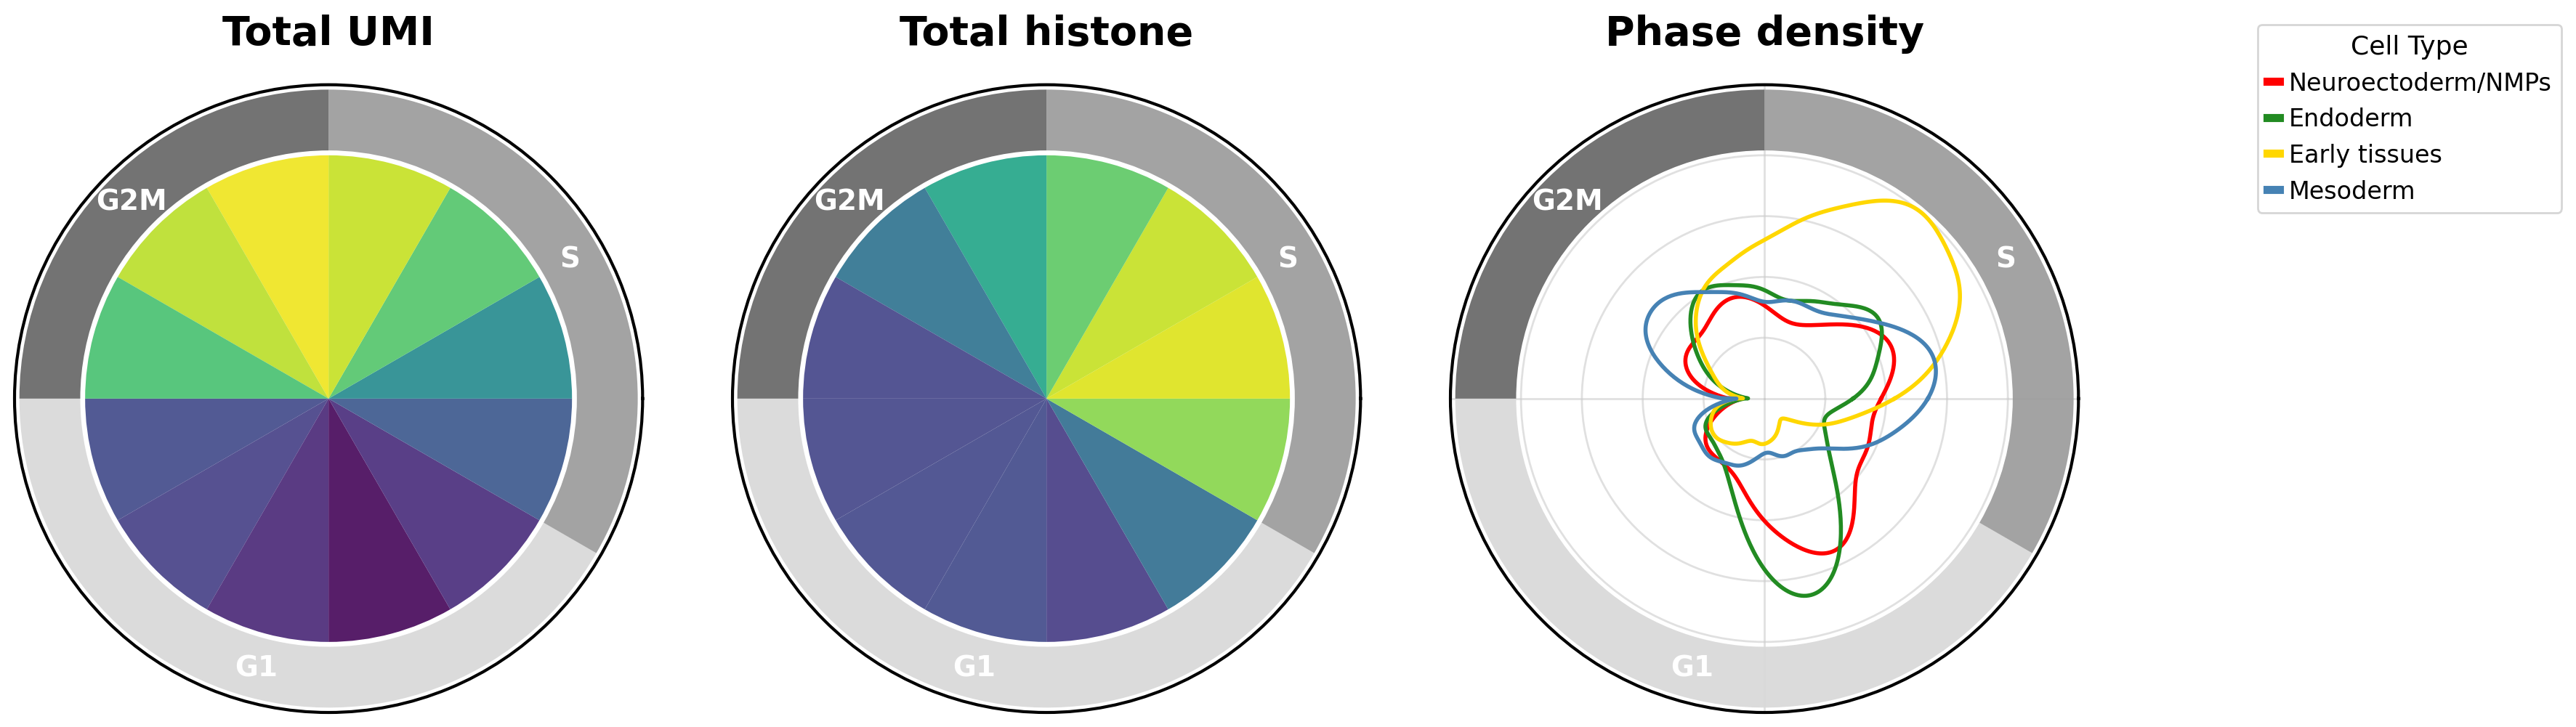

In [ ]:
def add_phase_band(ax, segments, r0=1.02, band_height=0.13, alpha=0.95, edgecolor="none"):
    def wrap(a):
        return (a + 2 * np.pi) % (2 * np.pi)

    for seg in segments:
        start = wrap(seg["start"])
        end = wrap(seg["end"])
        direction = seg.get("direction", "ccw").lower()
        col = seg.get("color", "lightgrey")

        if direction == "ccw":
            width = (end - start) % (2 * np.pi)
            start_draw = start
        elif direction == "cw":
            width = (start - end) % (2 * np.pi)
            start_draw = end
        else:
            raise ValueError("direction must be 'ccw' or 'cw'")

        center = start_draw + width / 2

        ax.bar(
            x=center,
            height=band_height,
            width=width,
            bottom=r0,
            color=col,
            alpha=alpha,
            edgecolor=edgecolor,
            align="center",
            zorder=5
        )
        ax.text(
            center,
            r0 + band_height / 2,
            seg["label"],
            fontsize=14,
            fontweight="bold",
            color="white",
            ha="center",
            va="center",
            zorder=6
        )

    ax.set_rlim(0, r0 + band_height + 0.02)


# Cell-type colours
color_map = {
    "Neuroectoderm/NMPs": "red",
    "Endoderm": "forestgreen",
    "Early tissues": "gold",
    "Mesoderm": "steelblue",
}

phase_segments = [
    {"label": "G1",  "start": np.pi,     "end": -np.pi/6, "direction": "ccw", "color": "#d9d9d9"},
    {"label": "S",   "start": -np.pi/6,  "end":  np.pi/2, "direction": "ccw", "color": "#9e9e9e"},
    {"label": "G2M", "start": np.pi/2,   "end":  np.pi,   "direction": "ccw", "color": "#6b6b6b"},
]

# Histone sums
histone_genes = [g for g in adata.var_names if g.startswith("hist")]
adata.obs["histone_sum"] = adata[:, histone_genes].X.sum(axis=1).A1

df = adata.obs[["inferred_theta", "histone_sum", "UMI_SUM", "BIG_celltype"]].copy()
df = df[df["BIG_celltype"].isin(color_map.keys())].copy()

# Binning
num_bins = 12
theta_bins = np.linspace(-np.pi, np.pi, num_bins + 1)
theta_centers = 0.5 * (theta_bins[:-1] + theta_bins[1:])
theta_centers_plot = (theta_centers + 2 * np.pi) % (2 * np.pi)

df["bin"] = pd.cut(df["inferred_theta"], bins=theta_bins, labels=False, include_lowest=True)

bg = (
    df.groupby("bin")
      .agg(umi=("UMI_SUM", "median"), histone=("histone_sum", "median"))
      .reindex(range(num_bins))
)

# Fixed colormap ranges
umi_norm  = Normalize(6600, 12500)
hist_norm = Normalize(0, 13)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={"projection": "polar"})

for ax in axes:
    ax.set_thetalim(0, 2 * np.pi)
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)
    ax.set_xticks([])
    ax.set_yticks([])

TITLE_FONTSIZE = 20

# (a) UMI ring
axes[0].bar(
    theta_centers_plot,
    height=1.0,
    width=2 * np.pi / num_bins,
    bottom=0.0,
    color=plt.cm.viridis(umi_norm(bg["umi"].values)),
    edgecolor="none",
    alpha=0.9,
    zorder=1
)
axes[0].set_rlim(0, 1.06)
axes[0].set_title("Total UMI", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)

# (b) Histone ring
axes[1].bar(
    theta_centers_plot,
    height=1.0,
    width=2 * np.pi / num_bins,
    bottom=0.0,
    color=plt.cm.viridis(hist_norm(bg["histone"].values)),
    edgecolor="none",
    alpha=0.9,
    zorder=1
)
axes[1].set_title("Total histone", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)

# (c) Phase density
bw_adjust = 0.5
theta_grid = np.linspace(-np.pi, np.pi, 512, endpoint=False)
theta_plot = (theta_grid + 2 * np.pi) % (2 * np.pi)
order = np.argsort(theta_plot)

densities, global_max = {}, 0.0
for ct in color_map:
    x = df.loc[df["BIG_celltype"] == ct, "inferred_theta"].dropna().values
    if x.size == 0:
        continue
    kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
    dens = kde(theta_grid[order])
    densities[ct] = dens
    global_max = max(global_max, float(np.nanmax(dens)))

for ct, dens in densities.items():
    dens_scaled = dens / global_max if global_max > 0 else dens
    th = np.r_[theta_plot[order], theta_plot[order][0] + 2 * np.pi]
    rr = np.r_[dens_scaled, dens_scaled[0]]
    axes[2].plot(th, rr, lw=2, color=color_map[ct], zorder=2)

axes[2].set_title("Phase density", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=20)
axes[2].set_xticks(np.deg2rad([0, 90, 180, 270]))
axes[2].set_xticklabels([])
axes[2].set_yticks([0.25, 0.5, 0.75, 1.0])
axes[2].set_yticklabels([])
axes[2].grid(True, linewidth=1, alpha=0.6)

# Phase band
for ax in axes:
    add_phase_band(ax, phase_segments, r0=1.02, band_height=0.25)

# Legend
handles = [Line2D([0], [0], lw=4, color=color_map[ct]) for ct in color_map]
fig.legend(
    handles,
    list(color_map.keys()),
    title="Cell Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=12,
    title_fontsize=13
)

plt.tight_layout()



plt.show()
